# YOLO26：车辆检测与车流量统计

本实验在目标检测基础上再走一步：**从“这张图里有几辆车”走到“一段时间内通过了多少辆车”**。
数据使用 [vehicle-counting-rtvul / vehicle-counting-tksu5 v4](https://universe.roboflow.com/vehicle-counting-rtvul/vehicle-counting-tksu5/dataset/4)
的正式 YOLO26 导出（CC BY 4.0），6,565 张图，5 个类别 `0=truck, 1=bicycle, 2=bus, 3=car, 4=motorcycle`。
导入时按原编号只做小写规范化，并有 3 行标注在源包里是分割多边形，已改写为其外接检测框（数量记录在 `provenance.json`）。

三个必须分清的概念：

| 任务 | 问题 | 需要的信息 |
|---|---|---|
| 车辆检测计数 | 这张图里有几辆车 | 每帧检测框 + 去重规则 |
| 车流量统计 | 一段时间内通过几辆车 | 跟踪 ID + 过线判定 |
| 通行率 | 每分钟通过多少辆 | 车流量 ÷ 视频时长 |

> **每个代码单元后面都跟着一个「预期输出」单元**，文字输出逐字摘录、图片以 `../assets/` 相对路径引用。
> 因此即使执行 **Kernel → Clear All Outputs**（或第一次打开时没有输出），也能对照本实验的真实结果；
> 重新执行后单元输出会再次出现，两者应一致。数字来自 2026-10-18 的 Apple 芯片 MPS 实跑（`env_dl_uv` 内核，
> 5 轮 / 320 像素 / `seed=42`，端到端 940.47 s），英文版同参数同种子跑出的结果与之一致，
> 完整说明见[实跑报告](../lessons/05-vehicle-counting-run-report.md)。

先把数据集放到课程数据目录。数据统一在仓库外的 DataSet 暂存区（课堂镜像为 `/workspace/DataSet/yolo`），
仓库根目录执行：

```powershell
uv run python .\english\scripts\import_vehicle_counting.py --from-staging
.\start-notebooks.ps1 -Language zh-CN -Module detection
```

`COURSE_SMOKE=1` 会改用 COCO8 做纯链路检查，不代表车辆实验；`COURSE_EPOCHS` 只缩短训练轮数。
视频默认使用 `build_traffic_demo_video.py` 由数据集真实车辆裁剪合成的短片（每辆车只出现一次、只过一次线，
因此有确定答案），也可用 `TRAFFIC_VIDEO=<自己的.mp4>` 换成自己的道路视频。

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "请选择项目的 Python 3.12 内核。"
assert version('torch').split("+")[0] == '2.14.1', "请选择项目锁定的运行环境。"
print("Python：", sys.version.split()[0])
print('torch' + "：", version('torch'))
print("运行模式：", '课堂默认训练参数')

Python： 3.12.12
torch： 2.14.1
运行模式： 课堂默认训练参数


**预期输出：**

```text
Python： 3.12.12
torch： 2.14.1
运行模式： 课堂默认训练参数
```

In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None:
    COURSE = next((p / "english" for p in [start, *start.parents]
                   if (p / "english" / "COURSE_ROOT").is_file()), None)
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
sys.path.insert(0, str(COURSE / "scripts"))

# 中文课程专用模块（图表中文字体）放在仓库根的 common/ 下，英文课程目录保持全英文。
CHINESE_ROOT = COURSE.parent if (COURSE.parent / "CHINESE_COURSE_ROOT").is_file() else None
if CHINESE_ROOT is not None:
    sys.path.insert(0, str(CHINESE_ROOT / "common"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'/Users/will/workspace/deep-learning-lab/english/data/torch-cache'

**预期输出：**

```text
'…/deep-learning-lab/english/data/torch-cache'
```

（输出里的 `…` 代表运行本 notebook 时所在机器的仓库绝对路径前缀，你在自己机器上执行会看到自己的路径。）

In [3]:
import json
import warnings

from collections import Counter

import numpy

MODULE = COURSE / "02-object-detection"
OUTPUT = COURSE.parent / "02-object-detection" / "outputs"
# Keep Ultralytics settings local to this edition, before importing the package.
os.environ["YOLO_CONFIG_DIR"] = str(OUTPUT / "ultralytics-config")
import cv2
import torch
from ultralytics import YOLO, settings
import ultralytics
from ultralytics.utils import set_logging
import matplotlib.pyplot as plt
import yaml
from detection_data import (prepare_vehicle_counting, VEHICLE_CLASSES, VEHICLE_DIRECTORY,
                            VEHICLE_SOURCE)
from traffic_counting import (VEHICLE_CLASSES as TALLY_CLASSES, LineCrossingCounter,
                              count_video, ground_truth_counts, tally_predictions)
from build_traffic_demo_video import build as build_demo_video

from course_zh import setup_chinese_fonts
print("图表中文字体：", setup_chinese_fonts(plt))

OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
settings.update({"datasets_dir": str(MODULE / "data"),
                 "weights_dir": str(OUTPUT / "weights"),
                 "runs_dir": str(OUTPUT / "runs")})
# Ultralytics redraws a per-iteration progress bar; inside a saved notebook every redraw
# becomes a stored output record, so raise its log level and read the curve from results.png.
set_logging(verbose=False)
torch.set_num_threads(4)
DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")

# Ultralytics turns on warn-only determinism (seed plus torch.use_deterministic_algorithms).
# On Apple Silicon the autograd kernel index_put_with_accumulate_mps has no deterministic
# implementation, so that warning repeats once per epoch and buries the training log. It is
# silenced here; the caveat stays real: on MPS a rerun matches in aggregate, not bit-for-bit.
warnings.filterwarnings(
    "ignore",
    message="index_put_with_accumulate_mps does not have a deterministic implementation")
PRETRAINED = "yolo11n.pt"      # COCO pretrained: zero-shot baseline with 80 classes.
FINETUNE = "yolo26n.pt"        # Base weights fine-tuned here on the five vehicle classes.
EPOCHS = int(os.environ.get("COURSE_EPOCHS", 1 if SMOKE else 5))
IMGSZ = 64 if SMOKE else 320
BATCH = 2 if SMOKE else 8
COUNTING_LINE = ((0, 320), (640, 320))   # Data images are square 640x640 exports.
print("Ultralytics 版本：", ultralytics.__version__)
print("计算设备：", DEVICE, "| 训练轮数：", EPOCHS, "| 输入尺寸：", IMGSZ, "| 冒烟测试：", SMOKE)

图表中文字体： PingFang SC
Ultralytics 版本： 8.4.177
计算设备： mps | 训练轮数： 5 | 输入尺寸： 320 | 冒烟测试： False


**预期输出：**

```text
图表中文字体： PingFang SC
Ultralytics 版本： 8.4.177
计算设备： mps | 训练轮数： 5 | 输入尺寸： 320 | 冒烟测试： False
```

## 1. 核对数据与类别映射

YOLO 每行标注为 `class_id x_center y_center width height`，坐标按图片宽高归一化。
导入器已核对 Roboflow 来源元数据、类别集合、划分独立性与跨集合重复图片；这里再读出实际数量，
并把「图片数」和「标注框数」分开看——车流量实验关心的是目标数量，不是图片数量。

In [4]:
if SMOKE:
    from detection_data import prepare_coco8
    DATA_CONFIG = str(prepare_coco8(MODULE / "data", OUTPUT / "coco8-smoke-vehicle.yaml"))
    print("这只是冒烟测试：用 COCO8 检查流程能否跑通，不是车辆实验的成绩。")
    EXPORT = None
else:
    EXPORT = MODULE / "data" / VEHICLE_DIRECTORY
    DATA_CONFIG = OUTPUT / "vehicle-counting-data.yaml"
    config, counts = prepare_vehicle_counting(EXPORT, DATA_CONFIG)
    provenance = json.loads((EXPORT / "provenance.json").read_text(encoding="utf-8"))
    print("类别映射：", dict(enumerate(config["names"])))
    print("校验后的划分规模：", {k: v for k, v in counts.items()})
    print("数据来源：", provenance["source"], "| 许可：", provenance["license"])
    print("数据集压缩包 SHA-256：", (provenance["archive_sha256"] or "未记录")[:16], "...")
    DATA_CONFIG = str(DATA_CONFIG)

类别映射： {0: 'truck', 1: 'bicycle', 2: 'bus', 3: 'car', 4: 'motorcycle'}
校验后的划分规模： {'train': {'images': 4708, 'boxes': 52668}, 'val': {'images': 1661, 'boxes': 18810}, 'test': {'images': 196, 'boxes': 2120}, 'segmentation_lines_normalised': 0}
数据来源： https://universe.roboflow.com/vehicle-counting-rtvul/vehicle-counting-tksu5 | 许可： CC BY 4.0
数据集压缩包 SHA-256： 3945432ed7ce76c9 ...


**预期输出：**

```text
类别映射： {0: 'truck', 1: 'bicycle', 2: 'bus', 3: 'car', 4: 'motorcycle'}
校验后的划分规模： {'train': {'images': 4708, 'boxes': 52668}, 'val': {'images': 1661, 'boxes': 18810}, 'test': {'images': 196, 'boxes': 2120}, 'segmentation_lines_normalised': 0}
数据来源： https://universe.roboflow.com/vehicle-counting-rtvul/vehicle-counting-tksu5 | 许可： CC BY 4.0
数据集压缩包 SHA-256： 3945432ed7ce76c9 ...
```

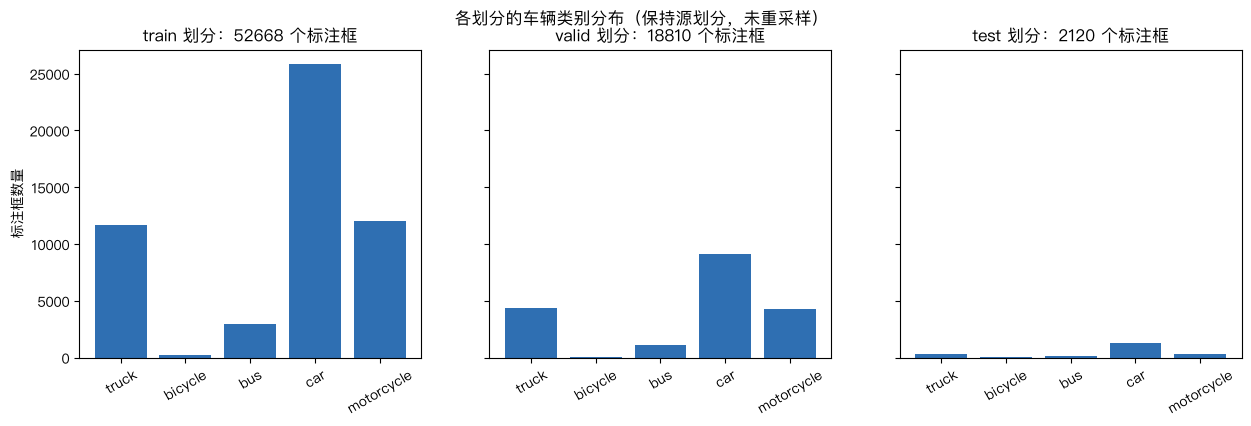

In [5]:
if SMOKE:
    print("COCO8 冒烟模式跳过车辆标注统计。")
else:
    def split_census(split):
        counter = Counter()
        for label in (EXPORT / split / "labels").glob("*.txt"):
            for line in label.read_text(encoding="utf-8").splitlines():
                fields = line.split()
                if len(fields) == 5:
                    counter[config["names"][int(fields[0])]] += 1
        return counter

    figure, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for axis, split in zip(axes, ("train", "valid", "test")):
        census = split_census(split)
        axis.bar(range(len(VEHICLE_CLASSES)), [census[name] for name in VEHICLE_CLASSES],
                 color="#2f6fb2")
        axis.set_xticks(range(len(VEHICLE_CLASSES)), VEHICLE_CLASSES, rotation=30)
        axis.set_title(f"{split} 划分：{sum(census.values())} 个标注框")
    axes[0].set_ylabel("标注框数量")
    figure.suptitle("各划分的车辆类别分布（保持源划分，未重采样）")
    plt.show()

**预期输出（图片）：**

![各划分标注框的类别分布（源划分未重采样）](../assets/vehicle-counting-1.png)

*各划分标注框的类别分布（源划分未重采样）*

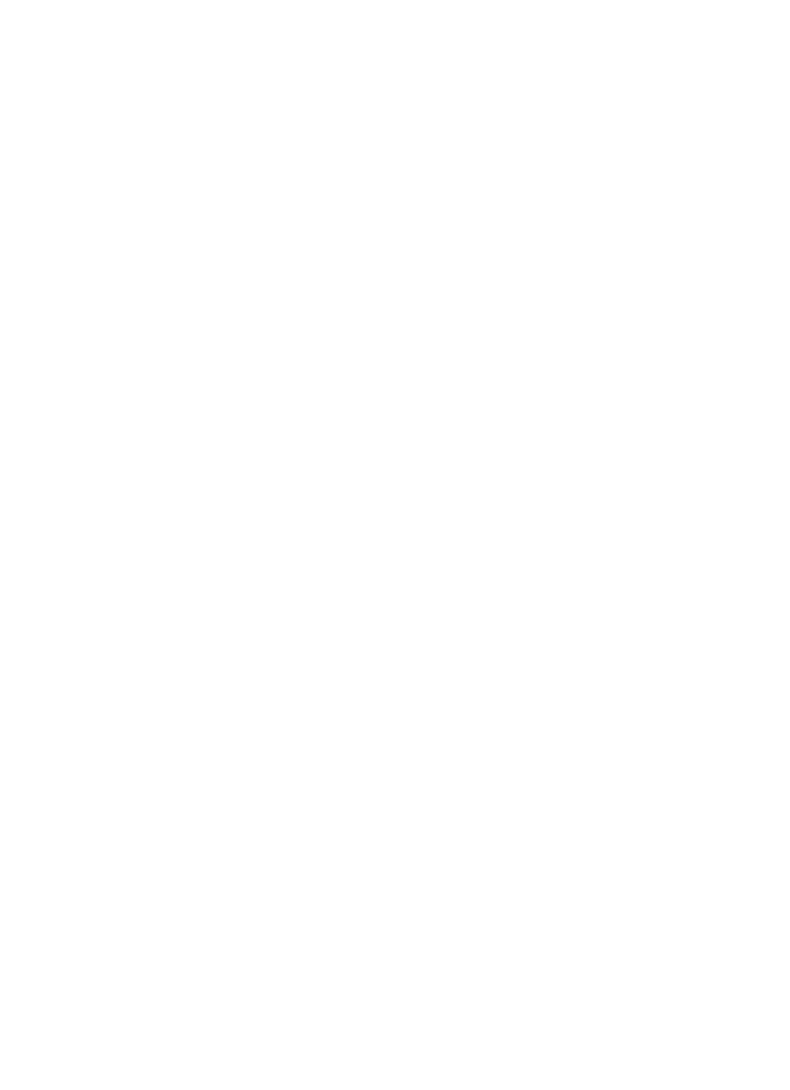

In [6]:
if SMOKE:
    print("COCO8 冒烟模式跳过每类样本网格。")
else:
    def show_class_samples(per_class=2, columns=3):
        rows = max(1, columns - 1)
        figure, axes = plt.subplots(len(VEHICLE_CLASSES), rows,
                                    figsize=(4 * rows, 2.2 * len(VEHICLE_CLASSES)))
        axes = numpy.atleast_2d(axes)
        for row, name in enumerate(VEHICLE_CLASSES):
            shown = 0
            for image in sorted((EXPORT / "valid" / "images").glob("*.jpg")):
                if shown == rows:
                    break
                label = image.with_name(image.stem + ".txt")
                if not label.exists():
                    continue
                lines = [l.split() for l in label.read_text(encoding="utf-8").splitlines()
                         if len(l.split()) == 5]
                hits = [f for f in lines if config["names"][int(f[0])] == name]
                if not hits:
                    continue
                picture = cv2.imread(str(image))
                height, width = picture.shape[:2]
                fields = hits[0]
                x, y, w, h = map(float, fields[1:])
                pad = 0.35
                left = max(0, int((x - w / 2 - w * pad) * width))
                right = min(width, int((x + w / 2 + w * pad) * width))
                top = max(0, int((y - h / 2 - h * pad) * height))
                bottom = min(height, int((y + h / 2 + h * pad) * height))
                axis = axes[row, shown] if rows > 1 else axes[row]
                axis.imshow(cv2.cvtColor(picture[top:bottom, left:right], cv2.COLOR_BGR2RGB))
                axis.set_title(f"{name} ({shown + 1})", fontsize=10)
                axis.axis("off")
                shown += 1
            for extra in range(shown, rows):
                axis = axes[row, extra] if rows > 1 else axes[row]
                axis.axis("off")
        plt.tight_layout()
        plt.show()

    show_class_samples()

**预期输出（图片）：**

![带框标注样本网格](../assets/vehicle-counting-2.png)

*带框标注样本网格*

## 2. 零样本对照：不改权重直接推理会怎样

COCO 预训练模型不认识本数据集的 5 个类别编号，但它本来就有 `car / bus / truck / motorcycle`
等车辆类。先把 COCO 类名映射到本课程的 5 类，再和本数据集真值比较。
这一步的教学目的：**先量出“不训练的误差”有多大**，再判断微调是否值得，以及计数误差来自哪里。

In [7]:
COCO_TO_COURSE = {"car": "car", "motorcycle": "motorcycle", "bus": "bus",
                  "truck": "truck", "pickup truck": "truck", "tractor": "truck"}

def ground_truth(image):
    # Labels live in the sibling labels/ directory, not next to the image.
    return ground_truth_counts(image, config["names"])

def tally_to_course(boxes, names):
    raw = tally_predictions(boxes, names, vehicle_classes=tuple(COCO_TO_COURSE))
    merged = Counter()
    for coco_name, quantity in raw["per_class"].items():
        merged[COCO_TO_COURSE[coco_name]] += quantity
    return dict(merged), raw["total"]

if SMOKE:
    print("COCO8 冒烟模式跳过零样本对比。")
else:
    zero_shot = YOLO(OUTPUT / "weights" / PRETRAINED)
    samples = sorted((EXPORT / "test" / "images").glob("*.jpg"))[:6]
    rows = []
    for image in samples:
        result = zero_shot.predict(str(image), conf=0.25, imgsz=IMGSZ, device=DEVICE,
                                   verbose=False)[0]
        predicted, total = tally_to_course(result.boxes, zero_shot.names)
        truth = ground_truth(image)
        rows.append((image.name[:34], sum(truth.values()), total,
                     sum(abs(truth.get(k, 0) - predicted.get(k, 0))
                         for k in set(truth) | set(predicted))))
    print(f"{'图片':<36} {'真实':>4} {'预测':>5} {'绝对误差':>9}")
    for name, gt, pred, error in rows:
        print(f"{name:36} {gt:4d} {pred:5d} {error:9d}")
    print("零样本平均绝对计数误差：",
          round(sum(r[3] for r in rows) / len(rows), 2), "辆/张图片")

图片                                     真实    预测      绝对误差
000000021136_jpg.rf.591a09eb79057b      5     3         2
000000279222_jpg.rf.fb7dc97a15f0d2      4     4         0
000000305803_jpg.rf.a12ac5644291b0     13     0        13
000000306789_jpg.rf.fbe2b1ca62b53a      1     1         0
000000306893_jpg.rf.4c136a12ec3d5c      2     4         2
000000314251_jpg.rf.6fc0048d77bbd3      9     0         9
零样本平均绝对计数误差： 4.33 辆/张图片


**预期输出：**

```text
图片                                     真实    预测      绝对误差
000000021136_jpg.rf.591a09eb79057b      5     3         2
000000279222_jpg.rf.fb7dc97a15f0d2      4     4         0
000000305803_jpg.rf.a12ac5644291b0     13     0        13
000000306789_jpg.rf.fbe2b1ca62b53a      1     1         0
000000306893_jpg.rf.4c136a12ec3d5c      2     4         2
000000314251_jpg.rf.6fc0048d77bbd3      9     0         9
零样本平均绝对计数误差： 4.33 辆/张图片
```

## 3. 微调 YOLO26n

`yolo26n.pt` 首次运行需要下载。课堂默认 5 轮、320 像素、batch 8；Apple 芯片 MPS 上每轮约 3 分钟，
`COURSE_EPOCHS=1` 是链路检查而非课堂结果。进度条已降级，损失与 mAP 曲线在下面直接展示。

已保存检查点： /Users/will/workspace/deep-learning-lab/02-object-detection/outputs/runs/vehicle-counting-v4-yolo26n-3/weights/best.pt


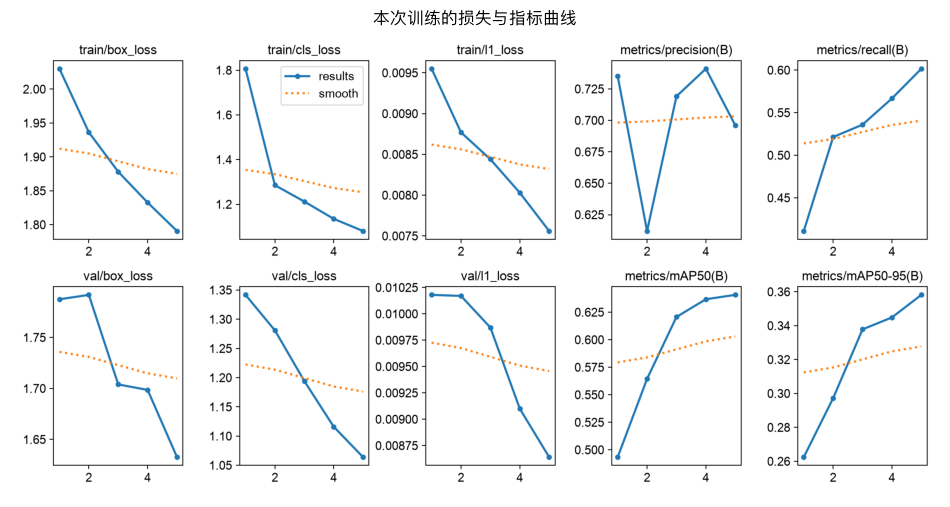

In [8]:
weights = OUTPUT / "weights" / FINETUNE
weights.parent.mkdir(parents=True, exist_ok=True)
model = YOLO(str(weights))
# Defaults are teaching parameters; runtime depends on the current dataset and hardware.
results = model.train(data=DATA_CONFIG, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, workers=0,
                      device=DEVICE, seed=42, deterministic=True, verbose=False,
                      project=str(OUTPUT / "runs"),
                      name="coco8-smoke-vehicle" if SMOKE else "vehicle-counting-v4-yolo26n",
                      exist_ok=False, plots=True)
best = Path(model.trainer.best)
if not best.exists():
    raise RuntimeError("训练没有产出 best 检查点。")
print("已保存检查点：", best)

curves = Path(model.trainer.save_dir) / "results.png"
if curves.exists():
    figure, axis = plt.subplots(figsize=(12, 8))
    axis.imshow(plt.imread(curves))
    axis.axis("off")
    axis.set_title("本次训练的损失与指标曲线")
    plt.show()
else:
    print("未找到预期图表：", curves)

**预期输出：**

```text
已保存检查点： …/deep-learning-lab/02-object-detection/outputs/runs/vehicle-counting-v4-yolo26n-3/weights/best.pt
```

（输出里的 `…` 代表运行本 notebook 时所在机器的仓库绝对路径前缀，你在自己机器上执行会看到自己的路径。）

**预期输出（图片）：**

![本次训练的曲线](../assets/vehicle-counting-3.png)

*本次训练的曲线*

## 4. 评估微调后的权重

验证集用于挑设置，测试集只做最终评估；`precision` 与 `recall` 在车流量场景里的含义不同：
误检会虚增流量，漏检会低估流量。逐类结果告诉你哪一类最容易出错（远处小车与遮挡车辆通常最差）。

test 划分精确率 precision：0.7308
test 划分召回率 recall：0.6444
test 划分 mAP50：0.6983
test 划分 mAP50-95：0.4071
指标报告已写出： /Users/will/workspace/deep-learning-lab/02-object-detection/outputs/vehicle-counting-metrics.json


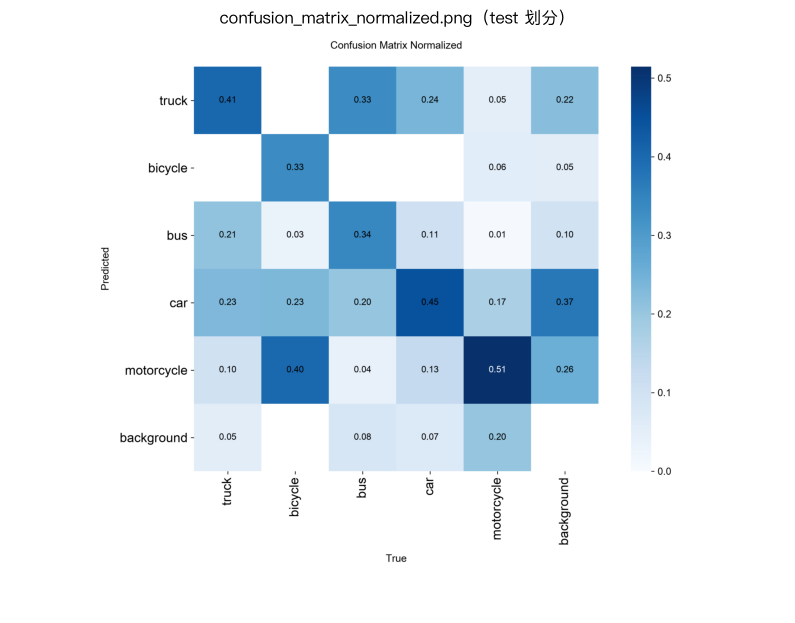

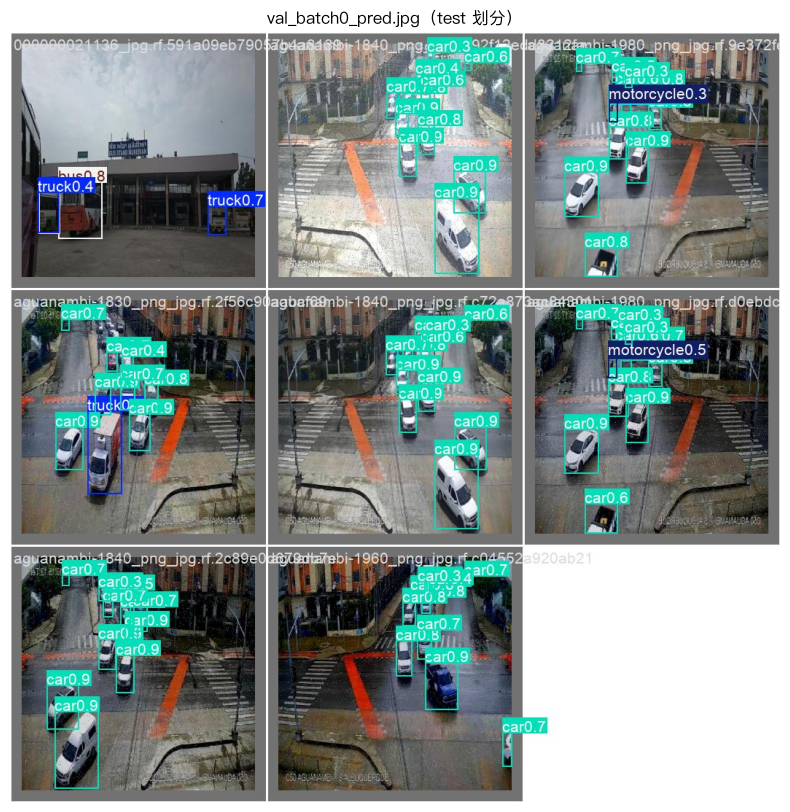

In [9]:
trained = YOLO(str(best))
if SMOKE:
    split, evaluation = "val", trained.val(data=DATA_CONFIG, split="val", device=DEVICE,
                                           imgsz=IMGSZ, workers=0, batch=BATCH,
                                           project=str(OUTPUT / "runs"), name="evaluation-smoke")
else:
    split, evaluation = "test", trained.val(data=DATA_CONFIG, split="test", device=DEVICE,
                                            imgsz=IMGSZ, workers=0, batch=BATCH,
                                            project=str(OUTPUT / "runs"),
                                            name="evaluation-vehicle")
print(f"{split} 划分精确率 precision：{evaluation.box.mp:.4f}")
print(f"{split} 划分召回率 recall：{evaluation.box.mr:.4f}")
print(f"{split} 划分 mAP50：{evaluation.box.map50:.4f}")
print(f"{split} 划分 mAP50-95：{evaluation.box.map:.4f}")
per_class = {}
ap_index = {int(c): i for i, c in enumerate(evaluation.box.ap_class_index)}
evaluated_names = dict(enumerate(config["names"])) if not SMOKE else dict(evaluation.names)
for class_id, name in evaluated_names.items():
    if SMOKE or class_id not in ap_index:
        per_class[name] = {"ap50": None, "ap50_95": None}
    else:
        position = ap_index[class_id]
        per_class[name] = {"ap50": float(evaluation.box.ap50[position]),
                           "ap50_95": float(evaluation.box.ap[position])}
report = {"smoke_test": SMOKE, "evaluation_split": split,
          "dataset": "COCO8" if SMOKE else VEHICLE_DIRECTORY,
          "dataset_provenance": {} if SMOKE else provenance,
          "precision": float(evaluation.box.mp), "recall": float(evaluation.box.mr),
          "map50": float(evaluation.box.map50), "map50_95": float(evaluation.box.map),
          "per_class": per_class, "epochs": EPOCHS, "imgsz": IMGSZ,
          "ultralytics_version": ultralytics.__version__}
(OUTPUT / ("smoke-vehicle-metrics.json" if SMOKE else "vehicle-counting-metrics.json")).write_text(
    json.dumps(report, indent=2), encoding="utf-8")
print("指标报告已写出：", OUTPUT / ("smoke-vehicle-metrics.json" if SMOKE
                                         else "vehicle-counting-metrics.json"))

for name in ("confusion_matrix_normalized.png", "val_batch0_pred.jpg"):
    figure_path = Path(evaluation.save_dir) / name
    if figure_path.exists():
        figure, axis = plt.subplots(figsize=(10, 10))
        axis.imshow(plt.imread(figure_path))
        axis.axis("off")
        axis.set_title(f"{name}（{split} 划分）")
        plt.show()
    else:
        print("未找到预期图表：", figure_path)

**预期输出：**

```text
test 划分精确率 precision：0.7308
test 划分召回率 recall：0.6444
test 划分 mAP50：0.6983
test 划分 mAP50-95：0.4071
指标报告已写出： …/deep-learning-lab/02-object-detection/outputs/vehicle-counting-metrics.json
```

（输出里的 `…` 代表运行本 notebook 时所在机器的仓库绝对路径前缀，你在自己机器上执行会看到自己的路径。）

**预期输出（图片）：**

![test 划分归一化混淆矩阵](../assets/vehicle-counting-4.png)

*test 划分归一化混淆矩阵*

**预期输出（图片）：**

![test 划分预测样例（蓝色 GT，青色预测）](../assets/vehicle-counting-5.png)

*test 划分预测样例（蓝色 GT，青色预测）*

## 5. 图片车流量：数清「这一帧里有几辆车」

用微调权重对整张图推理，按类别统计数量并画框。要点：

- 同一张图内不需要跟踪 ID，但仍要去掉低置信度抖动，所以 `conf` 阈值要写明。
- 只统计配置的 5 个车辆类别；万一一辆车被拆成两个框，数量就会偏大，这正是计数的误差来源之一。
- 把「模型预测数量」和「标注真值数量」并排打印，才能判断误差，而不是只看图好看。

000000021136_jpg.rf.591a09eb79057b4a8139188b25aabd95.jpg：预测 {'bus': 4, 'truck': 3} | 真实 {'bus': 4, 'truck': 1}
000000279222_jpg.rf.fb7dc97a15f0d237311be501e45f110a.jpg：预测 {'bus': 3, 'truck': 2, 'car': 1} | 真实 {'bus': 3, 'truck': 1}
000000305803_jpg.rf.a12ac5644291b03859ee97bf32999079.jpg：预测 {'motorcycle': 1} | 真实 {'motorcycle': 13}
000000306789_jpg.rf.fbe2b1ca62b53abcb7fb9fbc765b29e0.jpg：预测 {'motorcycle': 1} | 真实 {'motorcycle': 1}


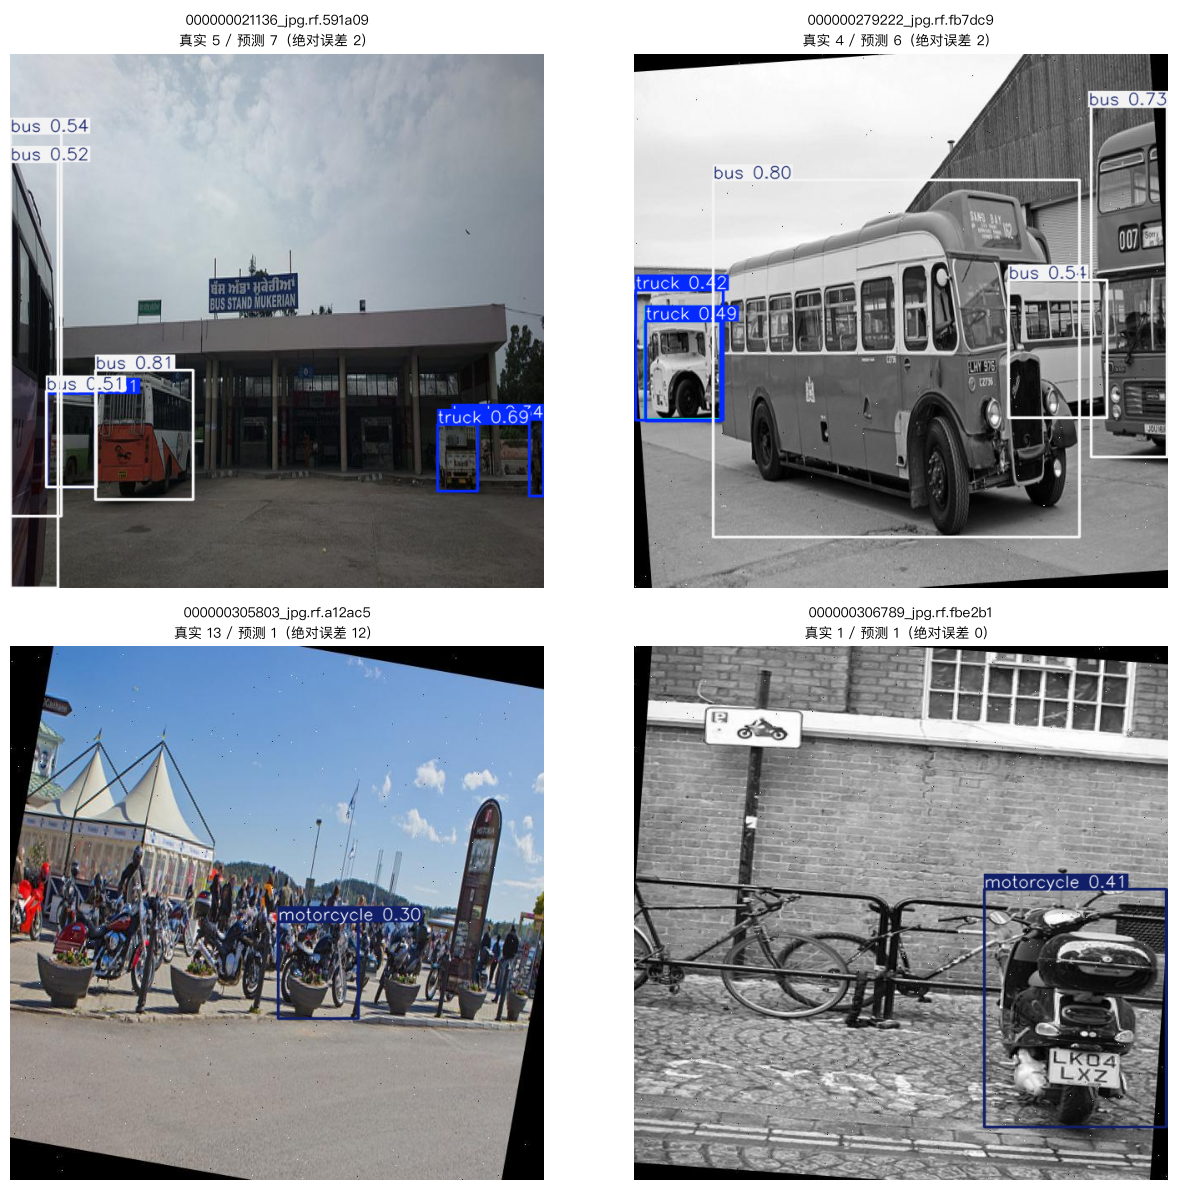

微调后平均绝对计数误差： 4.0 辆/张图片（这四张测试图）


In [10]:
if SMOKE:
    from ultralytics.utils import ASSETS
    image = ASSETS / "bus.jpg"
    result = trained.predict(str(image), conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    print("COCO8 冒烟模式预测到的类别：",
          tally_predictions(result.boxes, trained.names,
                            vehicle_classes=("car", "bus", "truck", "motorcycle")))
    plt.figure(figsize=(7, 6))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.title("COCO8 诊断用预测结果"); plt.axis("off"); plt.show()
else:
    grid = sorted((EXPORT / "test" / "images").glob("*.jpg"))[:4]
    figure, axes = plt.subplots(2, 2, figsize=(13, 12))
    errors = []
    for axis, image in zip(axes.ravel(), grid):
        result = trained.predict(str(image), conf=0.25, imgsz=IMGSZ, device=DEVICE,
                                 verbose=False)[0]
        tally = tally_predictions(result.boxes, trained.names, vehicle_classes=VEHICLE_CLASSES)
        truth = ground_truth(image)
        error = sum(abs(truth.get(k, 0) - tally["per_class"].get(k, 0))
                    for k in set(truth) | set(tally["per_class"]))
        errors.append(error)
        axis.imshow(result.plot()[:, :, ::-1])
        axis.set_title(f"{image.name[:26]}\n真实 {sum(truth.values())} / 预测 {tally['total']}"
                       f"（绝对误差 {error}）", fontsize=10)
        axis.axis("off")
        print(f"{image.name}：预测 {tally['per_class']} | 真实 {truth}")
    plt.tight_layout()
    plt.show()
    print("微调后平均绝对计数误差：", round(sum(errors) / len(errors), 2),
          "辆/张图片（这四张测试图）")

**预期输出：**

```text
000000021136_jpg.rf.591a09eb79057b4a8139188b25aabd95.jpg：预测 {'bus': 4, 'truck': 3} | 真实 {'bus': 4, 'truck': 1}
000000279222_jpg.rf.fb7dc97a15f0d237311be501e45f110a.jpg：预测 {'bus': 3, 'truck': 2, 'car': 1} | 真实 {'bus': 3, 'truck': 1}
000000305803_jpg.rf.a12ac5644291b03859ee97bf32999079.jpg：预测 {'motorcycle': 1} | 真实 {'motorcycle': 13}
000000306789_jpg.rf.fbe2b1ca62b53abcb7fb9fbc765b29e0.jpg：预测 {'motorcycle': 1} | 真实 {'motorcycle': 1}
微调后平均绝对计数误差： 4.0 辆/张图片（这四张测试图）
```

**预期输出（图片）：**

![四张 test 图片的检测与计数](../assets/vehicle-counting-6.png)

*四张 test 图片的检测与计数*

## 6. 视频车流量：跟踪 + 过线判定

逐帧数框会把同一辆车重复计入几十次，所以车流量必须做两件事：

1. **跟踪**（`model.track`，ByteTrack）给每辆车一个稳定 `tracker_id`；
2. **过线判定**：取框底边中点（车辆接地点）相对计数线的符号，符号翻转即视为过一次线，
   且每辆车每个方向只计一次，倒回去不会重复计数（实现见 `english/common/traffic_counting.py`）。

先用合成短片（`build_traffic_demo_video.py` 生成，已知 6 辆车各过一次线）验证计数器的正确性，
再用 `TRAFFIC_VIDEO=<自己的.mp4>` 换成真实道路视频做同一套流程。

In [11]:
VIDEO = Path(os.environ.get("TRAFFIC_VIDEO", str(OUTPUT / "traffic-demo.mp4")))
if VIDEO.exists():
    print("使用的视频：", VIDEO)
else:
    VIDEO.parent.mkdir(parents=True, exist_ok=True)
    truth = build_demo_video(MODULE / "data" / VEHICLE_DIRECTORY, VIDEO, fps=12, frames=108)
    print("已生成演示视频：", VIDEO)
    print("真实过线数量：", truth["expected_total_crossings"],
          truth["expected_vehicles_per_class"])
ground_truth_path = VIDEO.with_suffix(".ground-truth.json")
video_truth = json.loads(ground_truth_path.read_text(encoding="utf-8")) if ground_truth_path.exists() else None
if video_truth:
    print("计数线位置：", video_truth["counting_line"], "| 总帧数：", video_truth["frames"],
          "| 帧率：", video_truth["fps"])

使用的视频： /Users/will/workspace/deep-learning-lab/02-object-detection/outputs/traffic-demo.mp4
计数线位置： [0, 320, 640, 320] | 总帧数： 108 | 帧率： 12


**预期输出：**

```text
使用的视频： …/deep-learning-lab/02-object-detection/outputs/traffic-demo.mp4
计数线位置： [0, 320, 640, 320] | 总帧数： 108 | 帧率： 12
```

（输出里的 `…` 代表运行本 notebook 时所在机器的仓库绝对路径前缀，你在自己机器上执行会看到自己的路径。）

实际分析帧数： 108 ，声明总帧数 108 | 帧率： 12.0
forward 过线：  4  各类别：{'truck': 1, 'motorcycle': 1, 'bus': 2}
backward 过线：  2  各类别：{'bus': 2}
已计数车辆（去重）： 6 | 出现过的车辆跟踪轨迹数： 10
过线流向： {'duration_seconds': 9.0, 'total_crossings': 6, 'vehicles_per_minute': 40.0}
标注真实过线数量： 6 ，检测与跟踪偏差：+0


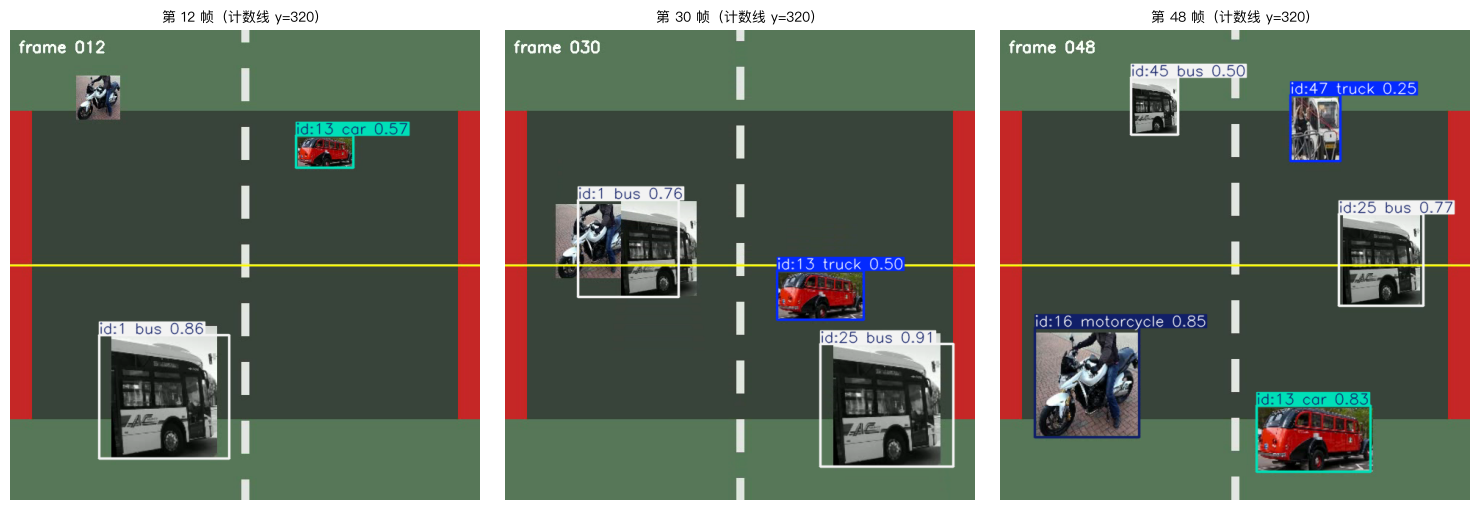

In [12]:
summary, frames = count_video(trained, VIDEO, COUNTING_LINE, conf=0.25,
                              imgsz=416 if not SMOKE else 64, device=DEVICE,
                              vehicle_classes=VEHICLE_CLASSES if not SMOKE else TALLY_CLASSES,
                              annotated_frames=(12, 30, 48))
print("实际分析帧数：", summary["frames_analysed"], "，声明总帧数", summary["declared_frames"],
      "| 帧率：", summary["fps"])
for direction in ("forward", "backward"):
    block = summary[direction]
    print(f"{direction} 过线：{block['crossings']:3d}  各类别：{block['per_class']}")
print("已计数车辆（去重）：", summary["unique_vehicles_seen"],
      "| 出现过的车辆跟踪轨迹数：", summary["tracks_observed"])
print("过线流向：", summary["flow"])
if video_truth:
    difference = summary["flow"]["total_crossings"] - video_truth["expected_total_crossings"]
    print("标注真实过线数量：", video_truth["expected_total_crossings"],
          f"，检测与跟踪偏差：{difference:+d}")

figure, axes = plt.subplots(1, max(1, len(frames)), figsize=(5 * max(1, len(frames)), 5))
axes = list(numpy.atleast_1d(axes))
for axis, sample in zip(axes, frames):
    axis.imshow(sample["rgb"])
    axis.set_title(f"第 {sample['frame']} 帧（计数线 y=320）", fontsize=10)
    axis.axis("off")
plt.tight_layout()
plt.show()

**预期输出：**

```text
实际分析帧数： 108 ，声明总帧数 108 | 帧率： 12.0
forward 过线：  4  各类别：{'truck': 1, 'motorcycle': 1, 'bus': 2}
backward 过线：  2  各类别：{'bus': 2}
已计数车辆（去重）： 6 | 出现过的车辆跟踪轨迹数： 10
过线流向： {'duration_seconds': 9.0, 'total_crossings': 6, 'vehicles_per_minute': 40.0}
标注真实过线数量： 6 ，检测与跟踪偏差：+0
```

**预期输出（图片）：**

![跟踪帧与过线（黄线 y=320）](../assets/vehicle-counting-7.png)

*跟踪帧与过线（黄线 y=320）*

## 7. 换成你自己的道路视频

同一个 `count_video()` 可以直接处理真实监控/行车记录仪视频，只需要按画面分辨率调整计数线：

```python
TRAFFIC_VIDEO = Path("/path/to/your-road-video.mp4")
summary, frames = count_video(trained, TRAFFIC_VIDEO,
                              line=((0, 0.55 * 1080), (1920, 0.55 * 1080)), conf=0.25)
print(summary["forward"]["crossings"], summary["backward"]["crossings"], summary["flow"])
```

调参顺序建议：先固定 `conf`，再调计数线位置，最后才动跟踪器参数。判定阈值一变，
流量数字就变，所以报告结论时必须同时写出线的位置、`conf` 与模型权重。

In [13]:
if SMOKE:
    print("COCO8 冒烟模式不会生成车流统计报告。")
else:
    traffic_report = {"video": summary["video"], "video_is_synthetic": video_truth is not None,
                      "model_checkpoint": str(best), "conf": 0.25, "tracker": "bytetrack.yaml",
                      "counting_line": summary["counting_line"],
                      "fps": summary["fps"], "frames_analysed": summary["frames_analysed"],
                      "counts": {d: summary[d] for d in ("forward", "backward")},
                      "unique_vehicles_counted": summary["unique_vehicles_seen"],
                      "vehicle_tracks_observed": summary["tracks_observed"],
                      "flow": summary["flow"],
                      "ground_truth": video_truth and video_truth["expected_total_crossings"],
                      "note": "Synthetic clip: every spawned vehicle crosses once, so the "
                              "deviation measures detection and tracking quality, not traffic."}
    (OUTPUT / "vehicle-flow-report.json").write_text(json.dumps(traffic_report, indent=2),
                                                     encoding="utf-8")
    print(json.dumps({k: traffic_report[k] for k in
                      ("counts", "unique_vehicles_counted", "flow")}, indent=2, ensure_ascii=False))

{
  "counts": {
    "forward": {
      "crossings": 4,
      "per_class": {
        "truck": 1,
        "motorcycle": 1,
        "bus": 2
      },
      "last_crossing": {
        "class": "bus",
        "track_id": 61,
        "frame": 78,
        "timestamp": 6.5
      }
    },
    "backward": {
      "crossings": 2,
      "per_class": {
        "bus": 2
      },
      "last_crossing": {
        "class": "bus",
        "track_id": 25,
        "frame": 52,
        "timestamp": 4.333333333333333
      }
    }
  },
  "unique_vehicles_counted": 6,
  "flow": {
    "duration_seconds": 9.0,
    "total_crossings": 6,
    "vehicles_per_minute": 40.0
  }
}


**预期输出：**

```text
{
  "counts": {
    "forward": {
      "crossings": 4,
      "per_class": {
        "truck": 1,
        "motorcycle": 1,
        "bus": 2
      },
      "last_crossing": {
        "class": "bus",
        "track_id": 61,
        "frame": 78,
        "timestamp": 6.5
      }
    },
    "backward": {
      "crossings": 2,
      "per_class": {
        "bus": 2
      },
      "last_crossing": {
        "class": "bus",
        "track_id": 25,
        "frame": 52,
        "timestamp": 4.333333333333333
      }
    }
  },
  "unique_vehicles_counted": 6,
  "flow": {
    "duration_seconds": 9.0,
    "total_crossings": 6,
    "vehicles_per_minute": 40.0
  }
}
```

## 练习与延伸

1. 把 `conf` 从 0.25 降到 0.10 再跑一次视频：过线数为什么会变，哪些类别先出现抖动？
2. 把计数线上下移动 100 像素，观察两个方向的车流量如何变化，解释原因（车辆出现/消失的位置）。
3. 只用检测不用跟踪（逐帧累加框数），对比两种口径的数字差距，说明为什么车流量必须跟踪。
4. 用 `TRAFFIC_VIDEO` 换一段真实视频，把线位置、`conf`、权重和逐类结果一起写进结论。
5. 想覆盖更多车型（如工程车、电动车），需要在原数据集补充标注或另找数据，再按同一导入流程入库。

来源与工具：[YOLO26 文档](https://docs.ultralytics.com/models/yolo26/)、
[ByteTrack 跟踪文档](https://docs.ultralytics.com/modes/track/)、
[数据集 v4](https://universe.roboflow.com/vehicle-counting-rtvul/vehicle-counting-tksu5/dataset/4)。